# Test Simulation

In [1]:
import numpy as np
import math as mp
import pandas as pd
import matplotlib.pyplot as plt

kwargs = {
    "tau" : 5.783,
    "mu_f" : -4.0,
    "sigma_f" : 1.85,
    "alpha_f" : 5.85
}

def norm( t_incub, ** kwargs ) :
    tau = kwargs["tau"]
    mu_f = kwargs["mu_f"]
    sigma_f = kwargs["sigma_f"]
    alpha_f = kwargs["alpha_f"]

    norm_const = sigma_f / alpha_f * ((1. + (t_incub/tau - 1.) * mp.pow(1. + mp.exp(mu_f / sigma_f), - alpha_f)) 
                                      - t_incub / tau * mp.pow(1. + mp.exp((mu_f + tau)/sigma_f), -alpha_f))
    return norm_const

def skew_logisitic_pdf(tost, t_incub, ** kwargs ) :
    tau = kwargs["tau"]
    mu_f = kwargs["mu_f"]
    sigma_f = kwargs["sigma_f"]
    alpha_f = kwargs["alpha_f"]


    if tost <= 0 :
        x = tost * tau / t_incub
    else :
        x = tost
    y = mp.exp((mu_f - x) / sigma_f) * mp.pow(1. + mp.exp((mu_f - x) / sigma_f), - alpha_f - 1.)
    
    return y / norm(t_incub, ** kwargs)

def skew_logisitic_cdf(tost, t_incub, thomas=False, ** kwargs) :
    tau = kwargs["tau"]
    mu_f = kwargs["mu_f"]
    sigma_f = kwargs["sigma_f"]
    alpha_f = kwargs["alpha_f"]

    if tost <= 0 :
        y = t_incub / tau * (mp.pow(1. + mp.exp((mu_f - tost[tost <= 0] * tau / t_incub) / sigma_f), -alpha_f) - mp.pow(1. + mp.exp((mu_f + tau) / sigma_f), -alpha_f))
    else :
        tmp = t_incub / tau * (mp.pow(1. + mp.exp(mu_f / sigma_f), -alpha_f) - mp.power(1. + mp.exp((mu_f + tau) / sigma_f), -alpha_f))
        y = tmp + mp.power(1. + mp.exp((mu_f - tost[tost > 0]) / sigma_f), -alpha_f) - mp.power(1. + mp.exp(mu_f / sigma_f), -alpha_f)

    return y * sigma_f / (alpha_f * norm(t_incub, thomas=thomas, ** kwargs))

## Perform a simulation on a single household

In [3]:
# make a choice for the test
HH_idx = 3

# fix the seed
random_state = 2

# load parameters from parameter file
file_name = "../data/database.txt"
database = pd.read_csv(file_name, sep=" ", index_col="index") 
mask = (database["HH_idx"] == HH_idx)
df_HH_raw = database[mask].astype(np.float64)
house_size = len(df_HH_raw)

# load parameters from parameter file
file_name = "../data/parameters.txt"
parameters = pd.read_csv(file_name, sep=" ", header=None, index_col=0) 

# load setup
file_name = "../data/setup.csv"
setup = pd.read_csv(file_name, sep=",", header=None, index_col=0) 
delta_t = np.float64(setup.at["delta_t", 1])

print("Chosen Household : ")
df_HH_raw

Chosen Household : 


,HH_idx,HH_size,onset_time,study_period,status,vacc_status,age,isol,sex,severity,vacc_delay,recov
index,,,,,,,,,,,,
7,3.0,5.0,232.0,253.0,1.0,2.0,38.0,0.0,2.0,0.0,176.0,0.0
8,3.0,5.0,1000.0,253.0,0.0,2.0,36.0,0.0,1.0,0.0,176.0,0.0
9,3.0,5.0,1000.0,253.0,0.0,0.0,2.0,0.0,2.0,0.0,0.0,0.0
10,3.0,5.0,1000.0,253.0,0.0,0.0,6.0,0.0,2.0,0.0,0.0,0.0
11,3.0,5.0,1000.0,253.0,0.0,0.0,4.0,0.0,1.0,0.0,0.0,0.0


Transmission Simulation : 


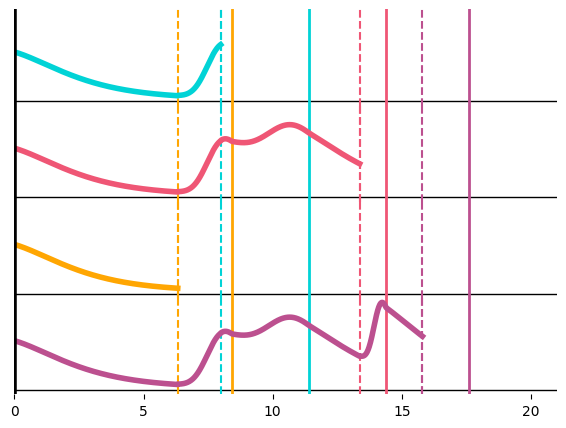

In [34]:
from scipy.stats import gamma

colors = ['#01D3D6', '#EF5675', '#FFA602', '#BC508F']

# load relevant parameters for dummy model
alpha = 0.005 #parameters.at["alpha", 1]
beta = 2.2 #parameters.at["beta", 1]
incub_shape  = parameters.at["incub_shape", 1]
incub_scale  = parameters.at["incub_scale", 1]

# find followup period
start_followup = df_HH_raw["onset_time"].min()
end_followup = df_HH_raw["study_period"].max()

# draw incubation periods 
df_HH = df_HH_raw[["status", "onset_time"]].copy()
df_HH["incub_period"] = gamma.rvs(incub_shape, scale=incub_scale, size=house_size, random_state=random_state)

# find first case and household infection time
first_case = df_HH.iloc[(df_HH["onset_time"] - df_HH["incub_period"]).argmin()].name
infec_time = (df_HH["onset_time"] - df_HH["incub_period"]).loc[first_case]

# set all other residents onset time time to infinity
df_HH.loc[df_HH.index != first_case, "onset_time"] = 1000.
df_HH.loc[df_HH.index != first_case, "status"] = 0

# initial list of infectors
infectors = list([first_case])
# initial list of susceptible
suscept = list(set(df_HH.index) - set(infectors))

# store all evolution of probability
store_proba = { s : pd.DataFrame() for s in suscept}
rng = np.random.default_rng(random_state)

for t in np.arange(infec_time, end_followup, delta_t) :
    # stop if all infected/recovered
    if len(suscept) == 0 :
        break

    # loop over susceptible
    else :
        to_change = []
        for s in suscept:

            # compute risk of infection
            roi = alpha
            for i in infectors :
                tost = t + delta_t - df_HH.at[i, "onset_time"]
                t_incub = df_HH.at[i, "incub_period"]
                roi += beta / house_size * skew_logisitic_pdf(tost, t_incub, ** kwargs) # CHECK ME : house_size or len(suscept)?
            
            proba = 1. - np.exp(-roi * delta_t)
            #proba = (1. - np.exp(-roi)) * delta_t

            # add to residents to change according to Bernoulli process
            if rng.uniform() < proba :
                to_change.append(s)

            # store the simulation step
            store_proba[s] = pd.concat([store_proba[s],
                                        pd.DataFrame({"time" : [t], "proba" : [proba]})])

        # implement changes
        for s in to_change :
            df_HH.at[s, "status"] = 1
            df_HH.at[s, "onset_time"] = t + delta_t + df_HH.at[s, "incub_period"]
            suscept.remove(s)
            infectors.append(s)

# PRINT
print("Transmission Simulation : ")
nrows = len(store_proba)
fig, ax = plt.subplots(nrows = nrows, figsize=(7, nrows*1.25), sharex=False, sharey=True)
fig.subplots_adjust(hspace=0)
for n, i in enumerate(store_proba) :
    ax[n].axhline(y=0, color="black", lw=1)
    ax[n].axvline(x=store_proba[i]["time"].values[-1], ls="--", color=colors[n])
    for m, j in enumerate(store_proba) :
        ax[n].axvline(x=store_proba[j]["time"].values[-1], ls="--", color=colors[m])
        ax[n].axvline(x=store_proba[j]["time"].values[-1] + df_HH.at[j, "incub_period"], ls="-", lw=2, color=colors[m])
    
for n, i in enumerate(store_proba) :
    ax[n].plot(store_proba[i]["time"], store_proba[i]["proba"], lw=4, color=colors[n])
    ax[n].axvline(x=start_followup, color="black", lw=4)
    [ax[n].spines[x].set_visible(False) for x in ["top", "bottom", "left", "right"]]
    ax[n].set_yticks([])
    ax[n].set_xticks([])
    ax[n].set_xlim([start_followup, end_followup])

xticks = np.arange(int(start_followup), int(end_followup), 5)
_ = ax[n].set_xticks( xticks)
_ = ax[n].set_xticklabels( xticks - xticks[0])

plt.savefig(f"simulation-HH{HH_idx}.pdf", dpi=300,
            bbox_inches='tight', transparent=True)

# Assessing Update of Infectivity Profile
In order to check if the simulation was updating correctly the infectivity profiels, I reproduced the same stochastic process of the cpp script, starting from the same randomnumber generators. Since the discretization returns the same bernoulli probability of infection at each time interval, I can believe that the cpp simulation is correct.

In [ ]:
file_name = "dummy-proba-train.txt"
df = pd.read_csv(file_name, sep=" ", header=None, names=["indiv", "time", "u", "proba"])

delta_t = 0.01

df_HH = pd.read_csv("../output/simulated.txt", sep=" ", dtype=np.float64)
alpha = 0.001
beta = 1.2

study_period = df_HH["study_period"].max()

first_case = df_HH.at[ np.argmin(df_HH["onset_time"] - df_HH["incub_period"]), "index"]
infec_time = (df_HH["onset_time"] - df_HH["incub_period"]).min()
df_HH.set_index("index", drop=True, inplace=True)
beta_frac = beta / len(df_HH)

df_HH.loc[df_HH.index != first_case, "onset_time"] = 1000.

infectors = list([first_case])
sus = list(set(df_HH.index) - set(infectors))

store = { s : pd.DataFrame() for s in sus}

np.random.seed(22345)
for j, t in enumerate(np.arange(infec_time, study_period, delta_t)) :
    if len(sus) == 0 :
        break
    else :

        # loop over susceptible
        to_change = []
        for x, s in enumerate(sus):

            # compute risk of infection
            roi = alpha
            for i in infectors :
                tost = t + delta_t - df_HH.at[i, "onset_time"]
                t_incub = df_HH.at[i, "incub_period"]
                roi += beta_frac * skew_logisitic_pdf(tost, t_incub, ** kwargs)
            
            proba = 1. - np.exp(-roi * delta_t)
            store[s] = pd.concat([store[s], pd.DataFrame({"time" : [t], "proba" : [proba]})])

            u = df[df["indiv"] == s]["u"].values[j]
            #u = np.random.rand()

            if u < proba :
                to_change.append(s)

        for s in to_change :
            df_HH.at[s, "onset_time"] = t + delta_t + df_HH.at[s, "incub_period"]
            sus.remove(s)
            infectors.append(s)
df_HH

In [ ]:
pd.read_csv("../output/simulated.txt", sep=" ", dtype=np.float64)

In [ ]:
plt.figure()

indiv_idx = 11

sim = df[df["indiv"] == indiv_idx]["proba"]
plt.plot(df[df["indiv"] == indiv_idx]["time"], sim, label="sim")

plt.plot(store[indiv_idx]["time"], store[indiv_idx]["proba"], label="python", ls="--")
plt.legend()